# Trực quan hóa baseline dự báo doanh thu


Nội dung:
- So sánh Naive, Moving Average (1 → 52 - tuần), Seasonal Naive (SN-13/26/39/52 - tuần theo quý)
- So sánh hiệu năng của các baseline trên các tập Val 2023, Val 2024 và Test 2025.
- Phân tích mức độ ổn định của từng nhóm mô hình.
- Lựa chọn baseline phù hợp nhất dựa trên các tiêu chí đánh giá.


In [57]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

def find_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "outputs" / "baseline").is_dir():
            return path
    raise FileNotFoundError(
        "Could not find the project root directory containing 'outputs/baseline'."
    )


PROJECT_ROOT = find_root()
base = PROJECT_ROOT / "outputs" / "baseline"

print(f"Project root: {PROJECT_ROOT}")
print(f"Baseline data: {base}")

Project root: D:\project_git\retail-revenue-forecasting
Baseline data: D:\project_git\retail-revenue-forecasting\outputs\baseline


In [58]:
val_2023 = pd.read_csv(base / "val_23_results.csv")
val_2024 = pd.read_csv(base / "val_24_results.csv")
test_all = pd.read_csv(base / "test_25_results.csv")
criteria = pd.read_csv(base / "selection_criteria.csv")
verification = pd.read_csv(base / "selection_criteria_verification.csv")
prediction_check = pd.read_csv(base / "prediction_check_25.csv")

ma = [f"MA-{w}" for w in range(1, 53)]
sn = ["SN-13", "SN-26", "SN-39", "SN-52"]
hw = ["HW-add", "HW-mul"]

print(
    f"Val 2023: {len(val_2023)} models | "
    f"Val 2024: {len(val_2024)} models | "
    f"Test 2025: {len(test_all)} models"
)

Val 2023: 60 models | Val 2024: 60 models | Test 2025: 60 models


## 1. Tổng quan hiệu năng các baseline
- Baseline 1: Naive
- Baseline 2: Moving Average (1–52 tuần)
- Baseline 3: Seasonal Naive (13, 26, 39 và 52 tuần)
- Baseline 4: Holt-Winters (Additive và Multiplicative)

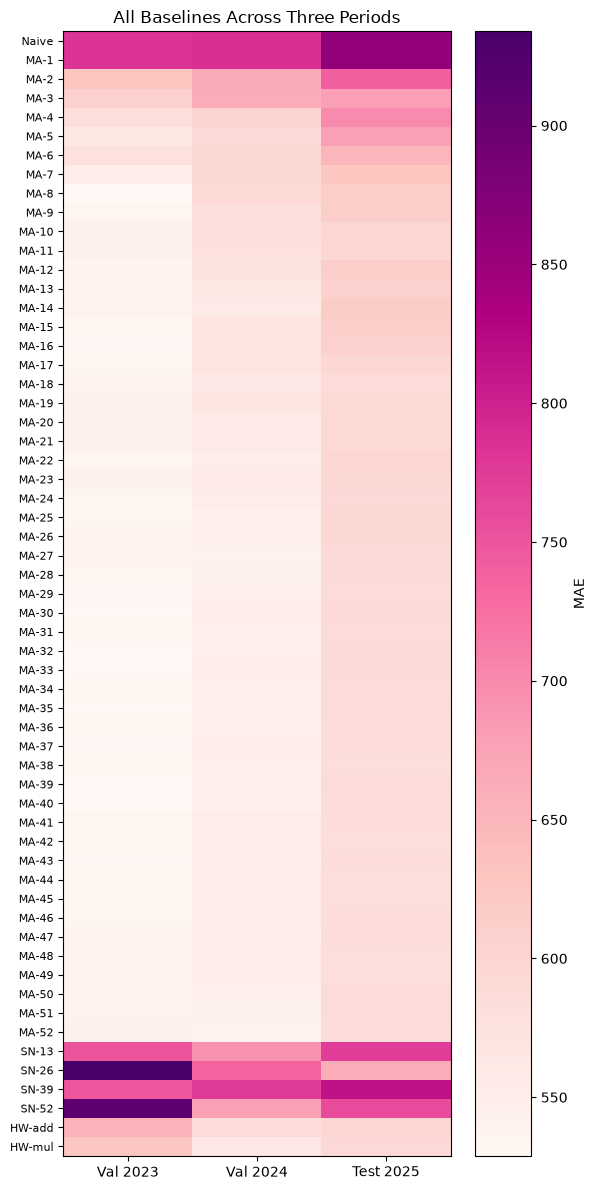

In [59]:
all_models_order = ["Naive"] + ma + sn + hw

pivot = pd.DataFrame({
    "Val 2023": val_2023.set_index("Baseline")["MAE"],
    "Val 2024": val_2024.set_index("Baseline")["MAE"],
    "Test 2025": test_all.set_index("Baseline")["MAE"],
}).reindex(all_models_order)

fig, ax = plt.subplots(figsize=(6, 12))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdPu")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=8)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_title("All Baselines Across Three Periods")
fig.colorbar(im, ax=ax, label="MAE")
plt.tight_layout()
plt.show()

**Nhận xét:**
- `Naive` và `MA-1` có màu đậm nhất ở cả ba giai đoạn cho kết quả sai số cao nhất vì đây là hai baseline "ngây thơ" nhất, gần như không làm mượt dữ liệu.
- Từ `MA-2` trở đi, MAE giảm mạnh và ổn định nhanh chóng tạo thành một dải sáng liên tục kéo dài suốt từ `MA-8` đến `MA-52` trên cả ba tập cho thấy MMA hội tụ về vùng tối ưu rất sớm và giữ ổn định trong một khoảng cửa sổ rộng, không nhạy cảm với việc chọn đúng window size.
- Nhóm `Seasonal Naive` (SN-13/26/39/52) có màu đậm rõ rệt, đặc biệt tại `val 23` (SN-26, SN-52 gần như đậm nhất bảng).
- `HW-add` và `HW-mul` cho màu sáng, tương đương vùng tốt nhất của MA trên cả ba giai đoạn - xác nhận Holt-Winters là một baseline mạnh ngang với Moving Average chứ không hề kém.
- Nhìn tổng thể, cột `test 25` có xu hướng đậm hơn hai cột val ở nhiều baseline (rõ nhất ở SN-39, SN-52, và cả dải MA ngắn) - phản ánh sai số tăng khi dự báo xa hơn vào dữ liệu chưa từng thấy, đúng với đặc điểm phổ biến của bài toán time series.

## 2. Phân phối MAE theo nhóm baseline

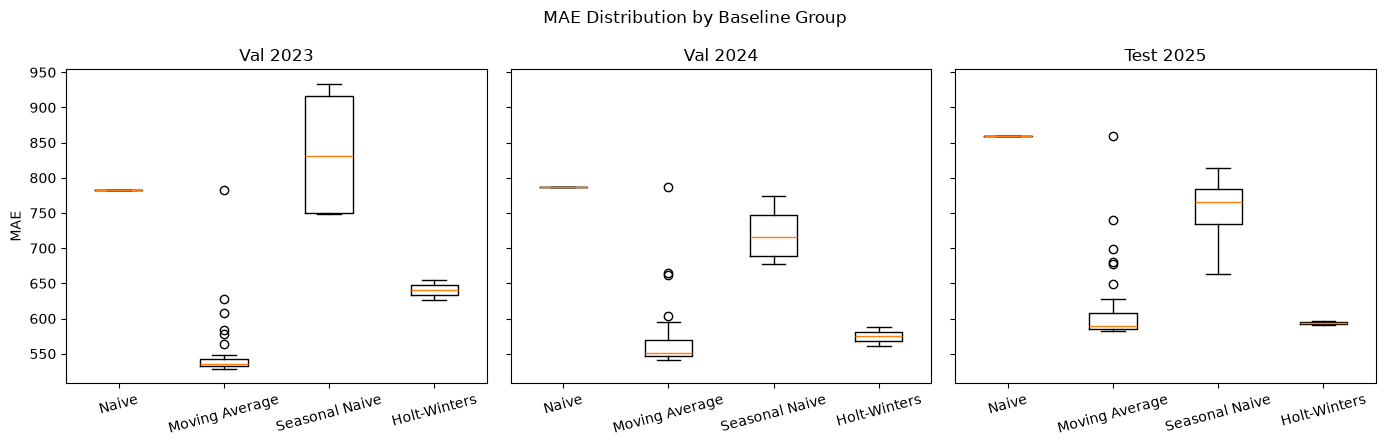

In [60]:
groups = {"Naive": ["Naive"], "Moving Average": ma, "Seasonal Naive": sn, "Holt-Winters": hw}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, (df, label) in zip(axes, [(val_2023, "Val 2023"), (val_2024, "Val 2024"), (test_all, "Test 2025")]):
    data_box = [df[df["Baseline"].isin(v)]["MAE"].values for v in groups.values()]
    ax.boxplot(data_box, tick_labels=list(groups.keys()))
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("MAE")
fig.suptitle("MAE Distribution by Baseline Group")
plt.tight_layout()
plt.show()

**Nhận xét:**
- `Moving Average` có mức trung vị MAE thấp nhất trên cả ba tập, thân hộp hẹp thể hiện độ ổn định cao. Các điểm ngoại lai phía trên là do sai số lớn ở những window nhỏ (MA-1, MA-2).
- `Holt-Winters` có thân hộp rất hẹp và nằm ở vị trí thấp - gần sát với `MA` trên `val 23` và `test 25`, thậm chí thấp hơn cả trung vị MA trên `val 24`. Đây là một baseline mạnh và ổn định chỉ nhỉnh hơn MA ở một vài giai đoạn.
- `Naive` có mức phân tán gần như bằng 0 nhưng nằm ở vị trí sai số cao trên  `val 23` và `val 24` cho thấy không bắt được biến động thực tế.
- `Seasonal Naive` có dải phân phối rộng nhất và vị trí trung vị cao (chỉ sau Naive) thể hiện sự thiếu ổn định rõ rệt giữa các mốc mùa vụ.
- Trên `test 25`, thứ tự median từ thấp đến cao là: `Holt-Winters` ≈ `Moving Average` < `Seasonal Naive` < `Naive`.

## 3. Phân tích Moving Average

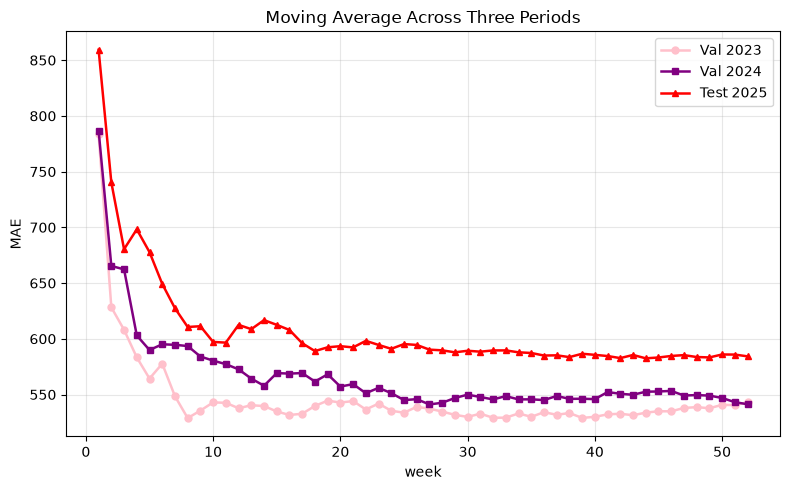

In [61]:
fig, ax = plt.subplots(figsize=(8, 5))
for df, label, style, color in [
        (val_2023, "Val 2023", "o-", "pink"),
        (val_2024, "Val 2024", "s-", "purple"),
        (test_all, "Test 2025", "^-", "red"),
    ]:
        sub = df[df["Baseline"].isin(ma)].copy()
        sub["window"] = sub["Baseline"].str.replace("MA-", "").astype(int)
        sub = sub.sort_values("window")
        ax.plot(sub["window"], sub["MAE"], style, label=label, linewidth=1.8, markersize=5, color=color)
ax.set_xlabel("week")
ax.set_ylabel("MAE")
ax.set_title("Moving Average Across Three Periods")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()



**Nhận xét:** 
- MAE của cả 3 tập đều bắt đầu ở mức rất cao nhưng giảm đột ngột và hội tụ nhanh chóng
- Khoảng 20-52 tuần duy trì ổn định, không có giao động lớn. 
- Ở tập `val 23` cho kết quả tốt nhất với mức sai số thấp nhất. Tập `val 24` cho kết quả đứng thứ 2, bám sát `val 23`. Trong khi đó, tập `test 25` có sai số cao nhất.

**Kết luận:** Ở các tuần đầu tiên thường là do mô hình thu thập và ổn định data. Với `test 25` có sai số cao hơn có khả năng do những yếu tố tương lai tác động.

## 4. Phân tích Seasonal Naive qua các giai đoạn

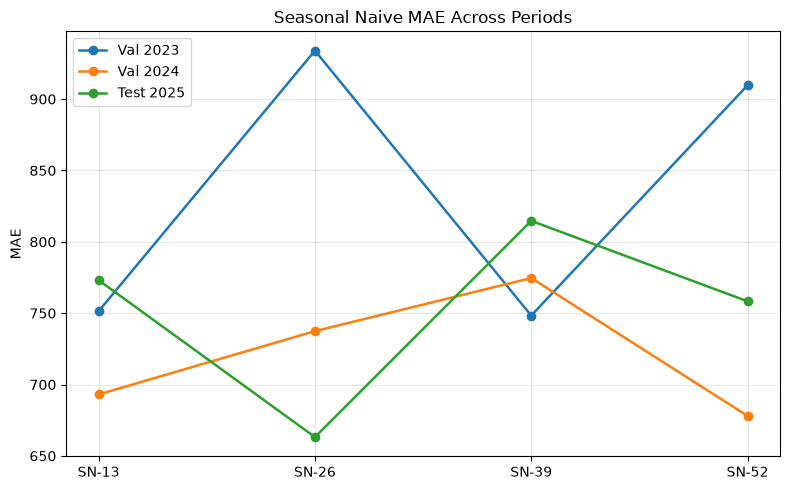

In [62]:
fig, ax = plt.subplots(figsize=(8, 5))
for df, label in [(val_2023, "Val 2023"), (val_2024, "Val 2024"), (test_all, "Test 2025")]:
    sub = df[df["Baseline"].isin(sn)].set_index("Baseline").reindex(sn)
    ax.plot(sn, sub["MAE"], marker="o", linewidth=1.8, label=label)

ax.set_ylabel("MAE")
ax.set_title("Seasonal Naive MAE Across Periods")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:** Hiệu xuất của SN qua các quý thiếu sự ổn định và biến động mạnh

- `val 23:` Có sự biến động dữ dội. Mức sai số tăng cao từ quý 1 (SN-13) sang quý 2 (SN-26) từ ~750 lên đến hơn 900. Tương tự mốc 4 quý (SN-52) cũng cho kết quả sai số cao gần bằng quý 2. Tuy nhiên ở giai đoạn chuyển dịch sang quý 3 (SN-39), sai số lại giảm mạnh về quanh mức 750.
- `val 24:`Dù sai số có xu hướng tăng dần từ quý 1 đến quý 3, nhưng lại giảm mạnh ở quý 4. mốc mùa vụ cho kết quả dự báo tốt nhất là 1 quý (SN-13) hoặc 4 quý (SN-52).
- `test 25:` Ngược lại, kết quả sai số ở mốc 2 quý (SN-26) đọt ngột giảm xuống mức thấp nhất (~660) trong khi ở mốc 1 quý (SN-13) và 3 quý (SN-39) lại tăng lên mức rất cao (đạt đỉnh tại quý 3) - trái ngược với tập `val 23` & `val 24`

**Kết luận:** Tính mùa vụ của dữ liệu thay đổi rất thất thường qua từng năm. Không có một chu kỳ cố định nào (dù theo quý hay theo năm) đảm bảo mang lại hiệu suất tốt nhất cho cả 3 tập dữ liệu.


## 5. Phân tích Holt-Winters (Additive vs Multiplicative)

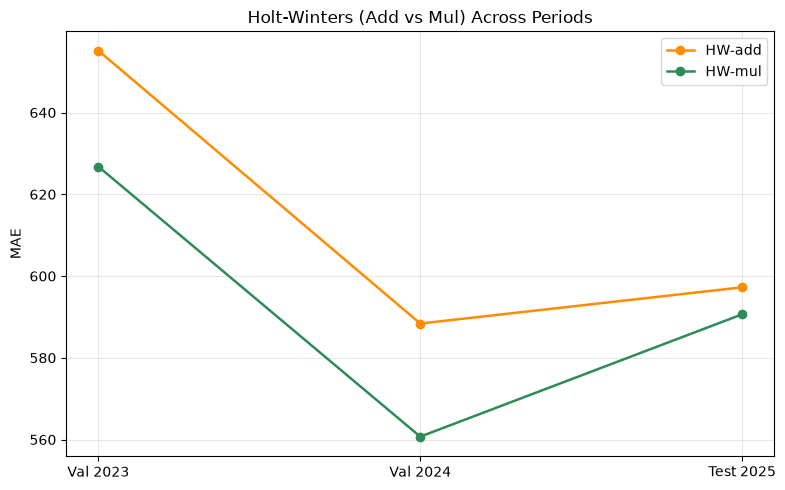

In [63]:
fig, ax = plt.subplots(figsize=(8, 5))
x = ["Val 2023", "Val 2024", "Test 2025"]
for model, color in [("HW-add", "darkorange"), ("HW-mul", "seagreen")]:
    y = [df.set_index("Baseline").loc[model, "MAE"] for df in (val_2023, val_2024, test_all)]
    ax.plot(x, y, marker="o", linewidth=1.8, label=model, color=color)

ax.set_ylabel("MAE")
ax.set_title("Holt-Winters (Add vs Mul) Across Periods")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:**
- `HW-mul` có MAE thấp hơn `HW-add` trên cả ba giai đoạn cho thấy multiplicative phù hợp hơn với dữ liệu này - biến động doanh thu có xu hướng tỷ lệ theo mức nền chứ không phải cộng cố định.
- Cả hai biến thể đều đạt MAE thấp nhất ở `val 24` (~560-588), cao hơn ở `val 23` (~627-655) và tăng nhẹ trở lại ở `test t25` (~590-597).
- Khoảng cách giữa `HW-add` và `HW-mul` lớn nhất ở `val 23` và gần như thu hẹp hoàn toàn ở `test t25` cho thấy mức độ ưu thế của multiplicative không ổn định qua các giai đoạn.
- Xu hướng chung: MAE giảm mạnh từ `val 23` sang  `val 24` rồi tăng nhẹ ở `test t25` - cùng pattern biến động theo giai đoạn đã thấy ở các baseline khác.

## 6. Tiêu chí lựa chọn mô hình

Sử dụng tập `val 23` & `val 24` để lựa chọn mô hình theo theo các tiêu chí đã đặt ra và dung tâho `test 25` để kiểm chứng lại. Kkhông sử dụng kết quả `test 25` để chọn mô hình nhằm tránh rò rỉ thông tin.
- **avg_MAE:** MAE trung bình trên hai tập validation.
- **avg_MASE:** MASE trung bình, được chuẩn hóa theo quy mô của từng năm.
- **avg_rank:** Thứ hạng trung bình của model, giúp giảm ảnh hưởng của các giá trị ngoại lai.
- **max_MAE:** Tiêu chí minimax, ưu tiên model có sai số trong trường hợp xấu nhất thấp nhất.
- **score_penalized:** MAE trung bình cộng với độ lệch chuẩn, nhằm phạt các model có kết quả thiếu ổn định.

In [65]:
verification_display = verification.copy()
verification_display["MAE"] = verification_display["MAE"].round(2)
verification_display["MASE"] = verification_display["MASE"].round(3)
verification_display

,Standard,Model,MAE,MASE
0,avg_MAE,MA-32,589.56,0.669
1,avg_MASE,MA-32,589.56,0.669
2,avg_rank,MA-32,589.56,0.669
3,max_MAE,MA-27,590.27,0.670
4,score_penalized,MA-27,590.27,0.670


## 7. Kiểm chứng mô hình trên tập Test 2025

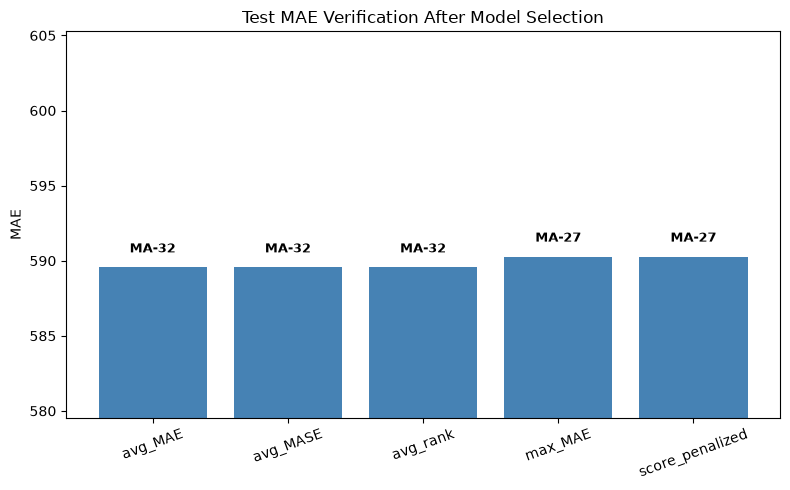

In [66]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(verification["Standard"], verification["MAE"], color="steelblue")
for bar, (_, row) in zip(bars, verification.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            row["Model"], ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("MAE")
ax.set_title("Test MAE Verification After Model Selection")
ax.set_ylim(verification["MAE"].min() - 10, verification["MAE"].max() + 15)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Nhận xét:**

* **Lựa chọn mô hình:** `MA-32` được chọn bởi 3/5 tiêu chí (`avg_MAE`, `avg_MASE`, `avg_rank`) — các tiêu chí dựa trên giá trị trung bình qua hai tập validation. `MA-27` được chọn bởi 2 tiêu chí còn lại (`max_MAE`, `score_penalized`) — các tiêu chí ưu tiên kiểm soát sai số trong trường hợp xấu nhất và phạt sự bất ổn định.
* **Kiểm chứng trên tập `test 25`:** `MA-32` đạt MAE khoảng 589.5, thấp hơn nhẹ so với `MA-27` (~590.3). Chênh lệch chỉ khoảng 0.7–0.8, cho thấy hai biến thể MA có mức độ ổn định tương đương nhau.
* không có tiêu chí nào chọn HW-add hay HW-mul cho thấy dù Holt-Winters mô hình hóa được cả trend lẫn seasonal vẫn không vượt qua được Moving Average trên tập dữ liệu này.

**Kết luận:** `MA-32` là lựa chọn phù hợp nhất theo kết quả tổng hợp từ 5 tiêu chí và tiếp tục là baseline mạnh nhất kể cả khi so sánh với một mô hình có cấu trúc phức tạp hơn (Holt-Winters). Đây là bằng chứng cho thấy bản chất seasonal/trend của doanh thu theo tuần trong dữ liệu này không đủ ổn định để một mô hình cấu trúc tường minh (HW) khai thác tốt hơn cách tiếp cận làm mượt đơn giản (MA). Ngưỡng benchmark `MAE ≈ 589.5` (MA-32) sẽ là mốc tham chiếu chính

## 8. Actual và Predicted của MA-32 trên tập Test 2025

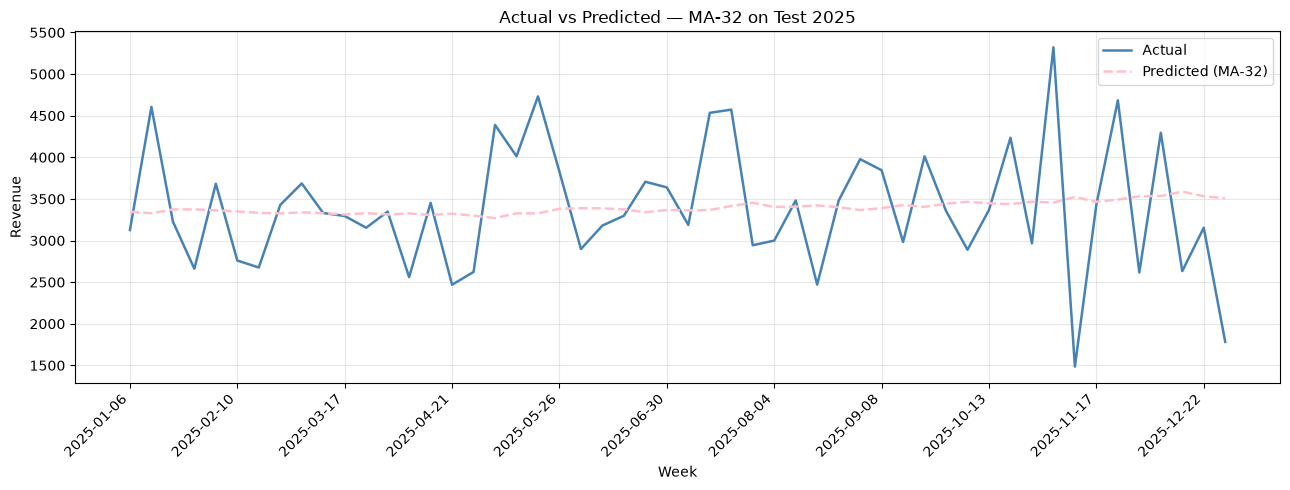

In [67]:
selected_models = verification["Model"]
BEST_MODEL = selected_models.mode().iloc[0]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(prediction_check["week_start"], prediction_check["actual"], label="Actual", linewidth=1.8, color="steelblue")
ax.plot(prediction_check["week_start"], prediction_check["predicted"], label=f"Predicted ({BEST_MODEL})", linewidth=1.8, linestyle="--", color="pink")
ax.set_title(f"Actual vs Predicted — {BEST_MODEL} on Test 2025")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue")
n_ticks = 10
step = max(len(prediction_check) // n_ticks, 1)
ax.set_xticks(range(0, len(prediction_check), step))
ax.set_xticklabels(prediction_check["week_start"].iloc[::step], rotation=45, ha="right")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:**
- `MA-32` được chọn bởi 3/5 tiêu chí: `avg_MAE`, `avg_MASE`, `avg_rank`.
- `MA-27` được chọn bởi 2 tiêu chí còn lại: `max_MAE`, `score_penalized`.
- Chênh lệch MAE giữa hai model rất nhỏ (~589.5 vs ~590.3) cho thấy cả hai đều có hiệu năng và độ ổn định tương đương nhau trên tập test.

**Kết luận:** `MA-32` là lựa chọn phù hợp nhất với đa số phiếu (3/5 tiêu chí) được chọn làm baseline chính thức cho các bước tiếp theo.

## 8. Kết luận

- **Moving Average** cho hiệu năng tốt và ổn định nhất trên cả `val 23`, `val 24` và `test 25`.
- Hiệu năng của Moving Average cải thiện rõ rệt khi tăng kích thước cửa sổ, khoảng 20–52 tuần cho kết quả ổn định hơn.
- **Holt-Winters** (cả `HW-add` và `HW-mul`) là một baseline mạnh và ổn định với MASE luôn dưới 1 trên cả ba giai đoạn, gần tiệm cận `Moving Average` - nhưng không vượt qua được MA trên bất kỳ tiêu chí lựa chọn nào.
- **Seasonal Naive** có hiệu năng biến động mạnh giữa các giai đoạn. Không có chu kỳ mùa vụ cố định nào cho kết quả tốt nhất trên cả ba tập dữ liệu.
- **Naive** có sai số cao nhất và không phản ánh tốt xu hướng biến động của doanh thu.

- Dựa trên các tiêu chí lựa chọn, `MA-32` được chọn là baseline phù hợp nhất với 3/5 tiêu chí. `MA-27` được chọn bởi 2 tiêu chí còn lại, chênh lệch MAE giữa hai model không đáng kể (~589.5 vs ~590.3).
- `MA-32` dự báo tốt mức doanh thu nền và xu hướng chung nhưng phản ứng chậm trước các biến động ngắn hạn do đặc tính làm mượt của `Moving Average`.
- Vì vậy, `MA-32` (MAE ≈ 589.5 trên `test 25`) được chọn làm baseline tham chiếu chính thức cho các mô hình nâng cao tiếp theo.